# Educational response representations: numerical reproduction

This notebook recomputes metrics, paired bootstrap intervals and figures from the included saved predictions for EdNet and Eedi. All displayed outputs are retained for inspection without running the notebook.

**Run all cells** using Python 3.10–3.12 after installing `requirements.txt`. The computation uses a CPU and calls `reproduce.py`; no GPU or raw dataset download is needed. This package reproduces numerical analyses from fitted predictions, rather than retraining the models.

B denotes IRT estimates and response summaries. Response SVD uses correctness information; exposure SVD uses observation indicators. Paired intervals use 5,000 resamples with the same resampling multiplicity for an ID across runs.

In [1]:
from pathlib import Path
import sys, subprocess, json, csv, html
from IPython.display import display, HTML, Image
ROOT = Path.cwd()
assert (ROOT / 'reproduce.py').is_file(), 'Open this notebook from the repository directory.'
run = subprocess.run([sys.executable, 'reproduce.py'], cwd=ROOT, capture_output=True, text=True)
print(run.stdout)
if run.returncode:
    raise RuntimeError(run.stderr)
results = json.loads((ROOT / 'output/results.json').read_text())
verification = json.loads((ROOT / 'output/verification.json').read_text())
print('Verification:', verification)


EdNet item complete
EdNet bundle complete
Eedi item complete
EdNet correctness complete
Eedi correctness complete
DONE: all recomputed statistics match the archived reference

Verification: {'passed': True, 'bootstrap_draws': 5000, 'absolute_tolerance': 1e-10}


In [2]:
def table(headers, rows):
    def cell(x):
        return html.escape(f'{x:.6f}' if isinstance(x, float) else str(x))
    content = '<table><thead><tr>' + ''.join('<th>'+cell(x)+'</th>' for x in headers) + '</tr></thead><tbody>'
    for row in rows:
        content += '<tr>' + ''.join('<td>'+cell(x)+'</td>' for x in row) + '</tr>'
    display(HTML(content + '</tbody></table>'))

def heading(text):
    display(HTML('<h3>'+html.escape(text)+'</h3>'))

def contrasts(key, selected=None):
    rows=[]
    for name, v in results[key]['contrasts'].items():
        if selected and name not in selected: continue
        rows.append([name, v['logloss_reduction'], *v['conditional_95_CI']])
    table(['Contrast (first vs second)', 'Log-loss reduction', '95% CI lower', '95% CI upper'], rows)


## Item classification
Five-run means. Smaller log loss and larger balanced accuracy/macro-F1 indicate better performance.

In [3]:
for dataset in ['EdNet', 'Eedi']:
    heading(dataset)
    table(['Input', 'Log loss', 'Balanced accuracy', 'macro-F1'],
          [[m]+[v[k]['mean'] for k in ['logloss','balanced_accuracy','macro_f1']]
           for m,v in results[dataset+'_item']['methods'].items()])
    contrasts(dataset+'_item')

Input,Log loss,Balanced accuracy,macro-F1
frequency,1.690269,0.142857,0.085494
B,1.538391,0.184249,0.160279
CDLD,1.367956,0.286490,0.285221
B_CDLD,1.274364,0.343751,0.348266
responseSVD,0.212095,0.948909,0.950643
B_responseSVD,0.203470,0.950138,0.951852
exposureSVD,0.043639,0.997449,0.996682
B_exposureSVD,0.040277,0.996664,0.995890


Contrast (first vs second),Log-loss reduction,95% CI lower,95% CI upper
B_CDLD_vs_B,0.264026,0.251357,0.276714
B_CDLD_vs_B_responseSVD,-1.070895,-1.106505,-1.035106
B_CDLD_vs_B_exposureSVD,-1.234087,-1.255735,-1.212422
CDLD_vs_responseSVD,-1.155861,-1.191670,-1.118469
CDLD_vs_exposureSVD,-1.324317,-1.345788,-1.302074


Input,Log loss,Balanced accuracy,macro-F1
frequency,1.259665,0.250000,0.153786
B,1.242055,0.257426,0.184356
CDLD,1.245248,0.253376,0.168960
B_CDLD,1.238122,0.265240,0.205304
responseSVD,0.954795,0.462270,0.485649
B_responseSVD,0.949742,0.464186,0.488824
exposureSVD,0.913178,0.491413,0.510782
B_exposureSVD,0.910196,0.498990,0.519358


Contrast (first vs second),Log-loss reduction,95% CI lower,95% CI upper
B_CDLD_vs_B,0.003933,0.002277,0.005680
B_CDLD_vs_B_responseSVD,-0.288380,-0.297357,-0.279293
B_CDLD_vs_B_exposureSVD,-0.327927,-0.337266,-0.317983
CDLD_vs_responseSVD,-0.290453,-0.299907,-0.281078
CDLD_vs_exposureSVD,-0.332071,-0.341727,-0.321977


## Response correctness
All rate-augmented predictors receive the training item proportion correct. Positive log-loss reduction favors the first condition in each contrast.

In [4]:
for dataset in ['EdNet', 'Eedi']:
    heading(dataset)
    table(['Predictor / input', 'Log loss', 'AUC', 'Brier score', 'Accuracy'],
          [[m]+[v[k]['mean'] for k in ['logloss','auc','brier','accuracy']]
           for m,v in results[dataset+'_correctness']['methods'].items() if m.endswith('_rate')])
    contrasts(dataset+'_correctness', [f'{k}_CDLD_rate_vs_{k}_{m}_rate'
               for k in ['MLP','bilinear'] for m in ['responseSVD','exposureSVD']])

Predictor / input,Log loss,AUC,Brier score,Accuracy
MLP_CDLD_rate,0.522018,0.771438,0.174415,0.739430
MLP_responseSVD_rate,0.573102,0.753271,0.183732,0.732050
MLP_exposureSVD_rate,0.528034,0.763040,0.176732,0.736320
bilinear_CDLD_rate,0.524244,0.769235,0.175263,0.738500
bilinear_responseSVD_rate,0.569305,0.724636,0.190988,0.712930
bilinear_exposureSVD_rate,0.546181,0.740672,0.183539,0.725390
item_rate,0.560017,0.718222,0.189383,0.715890


Contrast (first vs second),Log-loss reduction,95% CI lower,95% CI upper
MLP_CDLD_rate_vs_MLP_responseSVD_rate,0.051084,0.047386,0.054892
MLP_CDLD_rate_vs_MLP_exposureSVD_rate,0.006016,0.004074,0.008089
bilinear_CDLD_rate_vs_bilinear_responseSVD_rate,0.045061,0.042627,0.047530
bilinear_CDLD_rate_vs_bilinear_exposureSVD_rate,0.021937,0.019700,0.024370


Predictor / input,Log loss,AUC,Brier score,Accuracy
MLP_CDLD_rate,0.520503,0.793930,0.174374,0.737030
MLP_responseSVD_rate,0.528061,0.787095,0.177040,0.734210
MLP_exposureSVD_rate,0.562753,0.745039,0.191236,0.706250
bilinear_CDLD_rate,0.549298,0.762344,0.185953,0.714780
bilinear_responseSVD_rate,0.545230,0.770349,0.183595,0.722930
bilinear_exposureSVD_rate,0.589553,0.705723,0.202262,0.682800
item_rate,0.598954,0.687479,0.206497,0.674850


Contrast (first vs second),Log-loss reduction,95% CI lower,95% CI upper
MLP_CDLD_rate_vs_MLP_responseSVD_rate,0.007558,0.005422,0.009706
MLP_CDLD_rate_vs_MLP_exposureSVD_rate,0.042250,0.038482,0.045984
bilinear_CDLD_rate_vs_bilinear_responseSVD_rate,-0.004068,-0.007220,-0.001043
bilinear_CDLD_rate_vs_bilinear_exposureSVD_rate,0.040255,0.036394,0.044110


## Figures 1–4 and S1–S2
Workflow, classification, correctness, cross-task comparison, SVD inputs and Eedi domain recall.

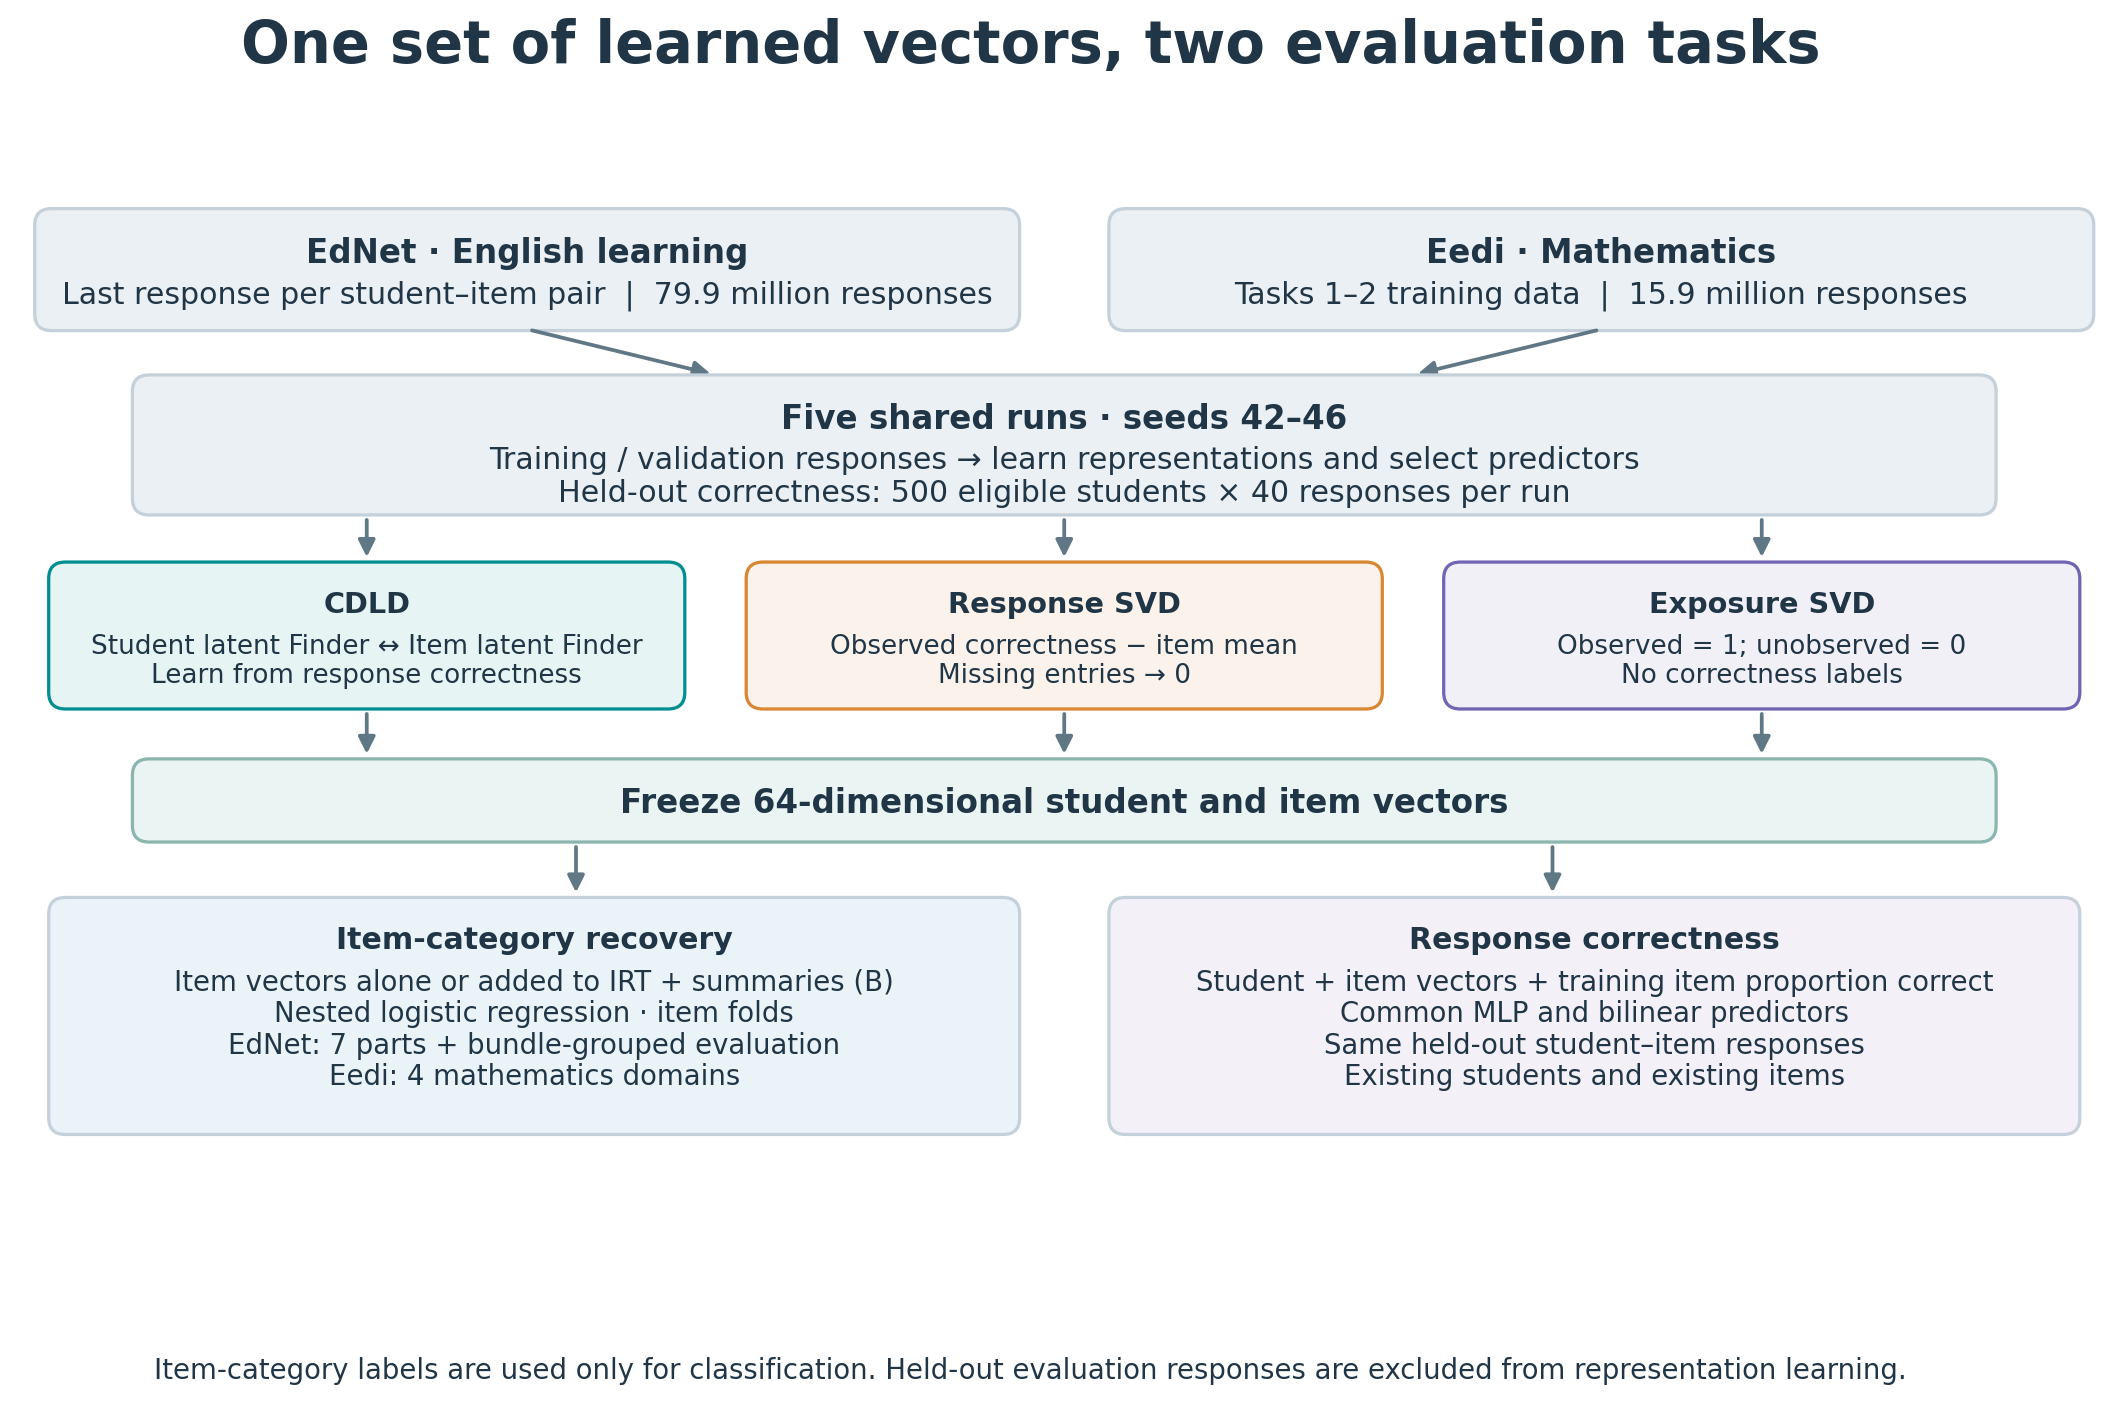

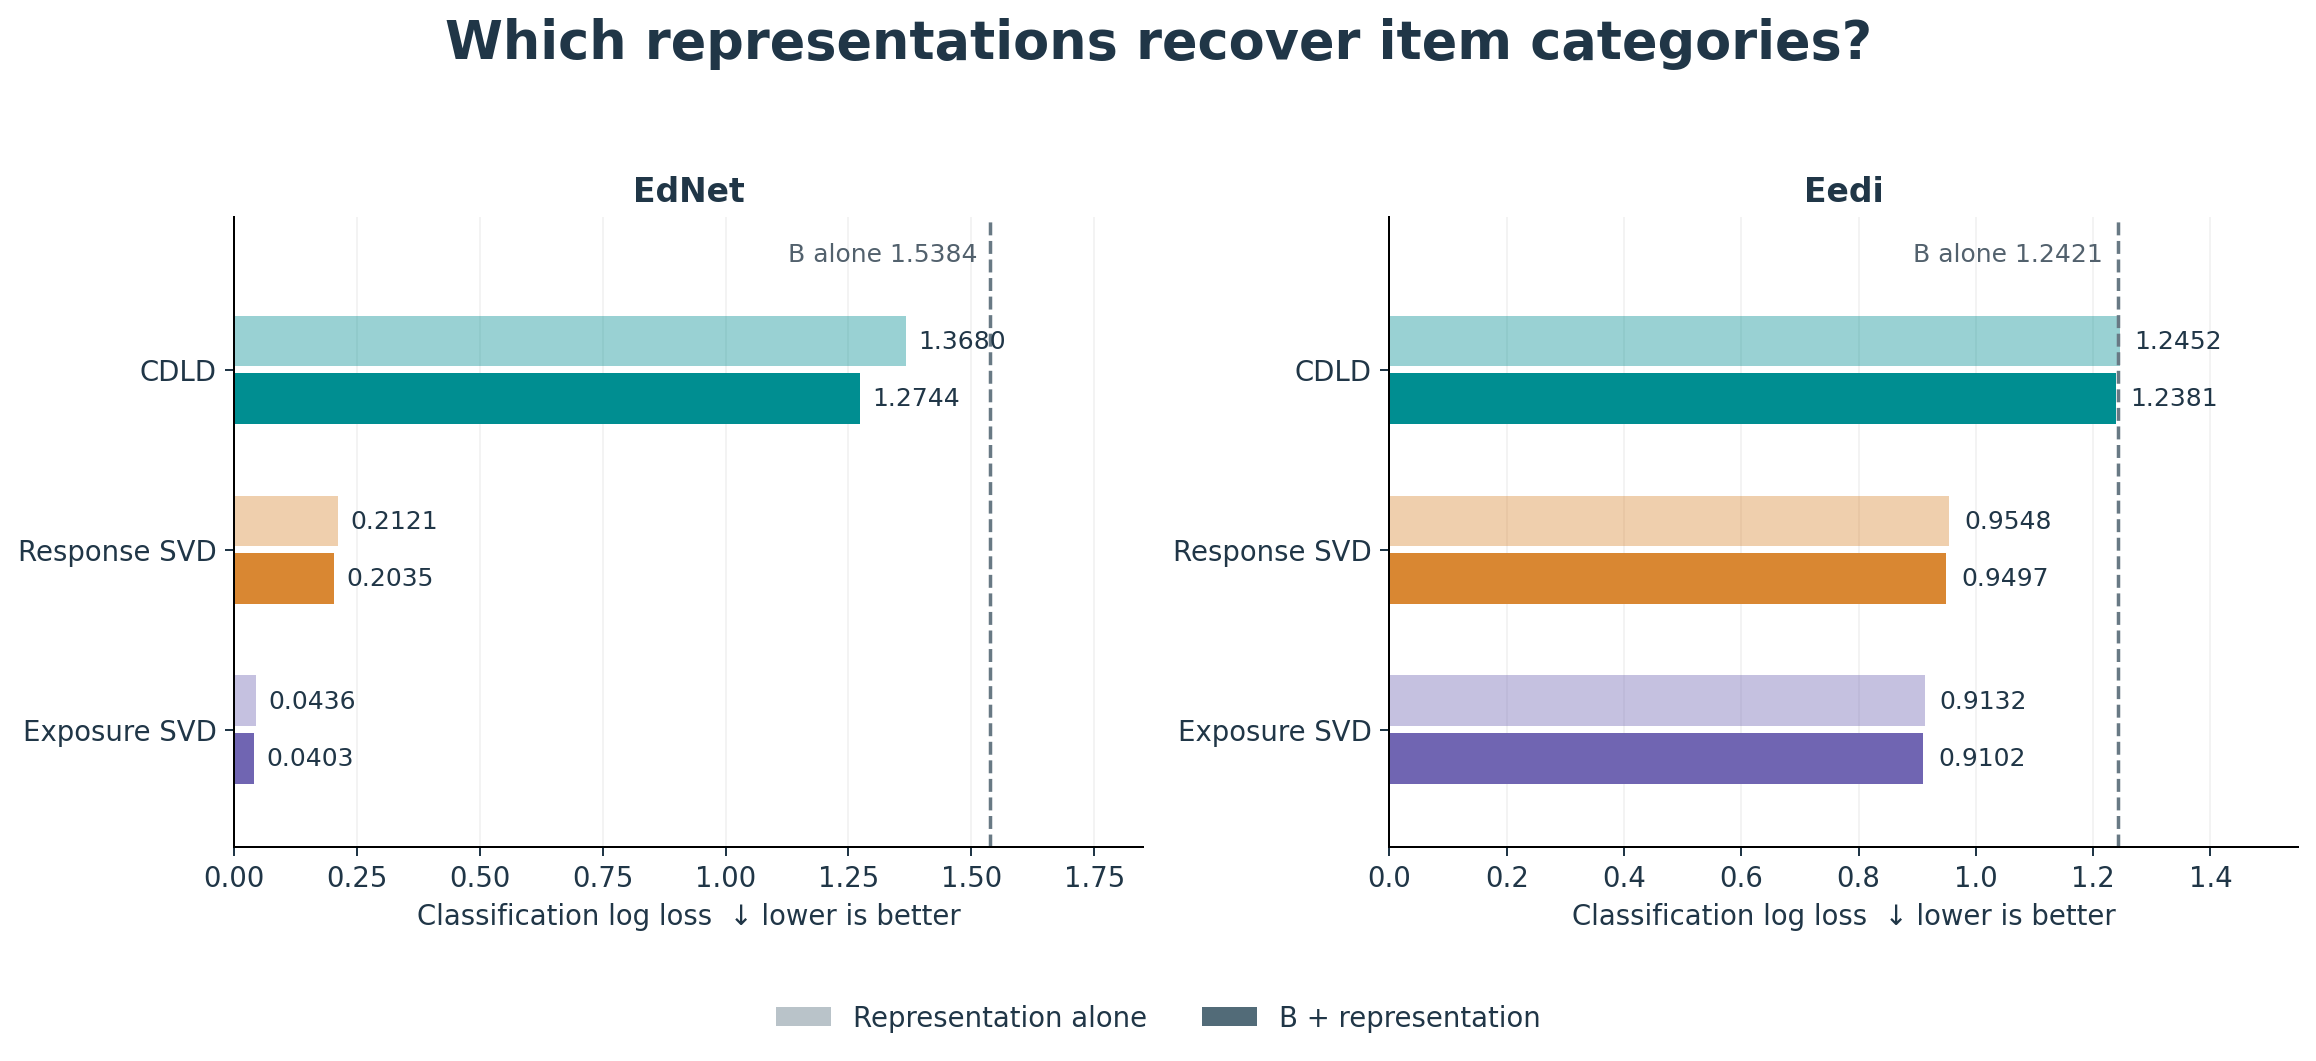

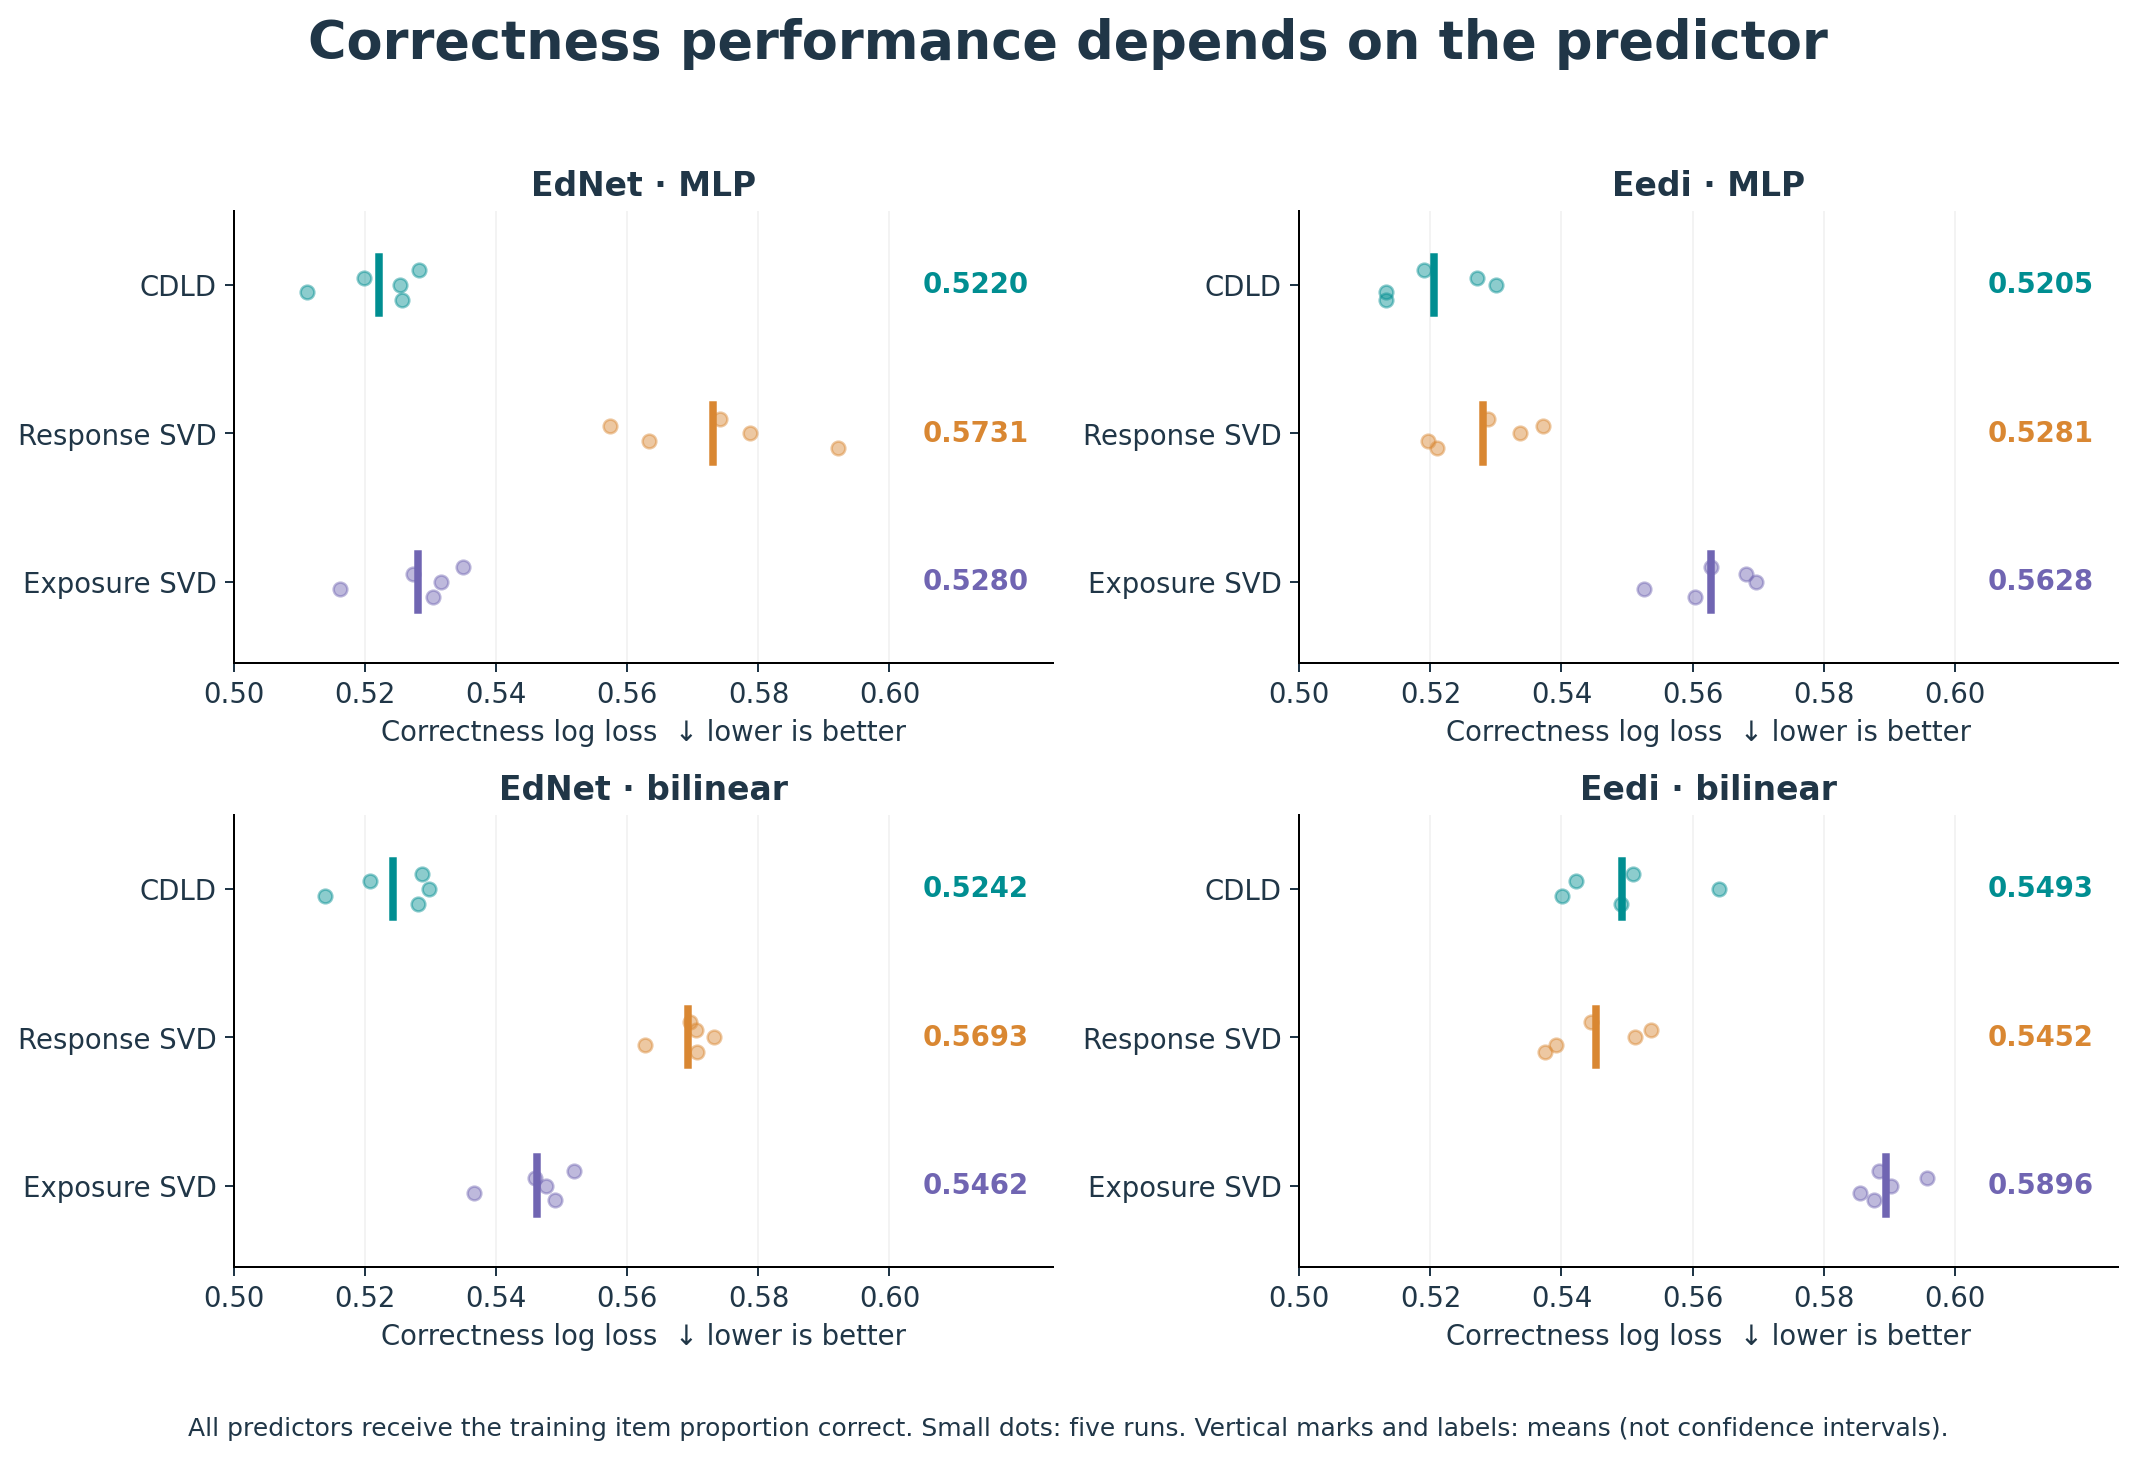

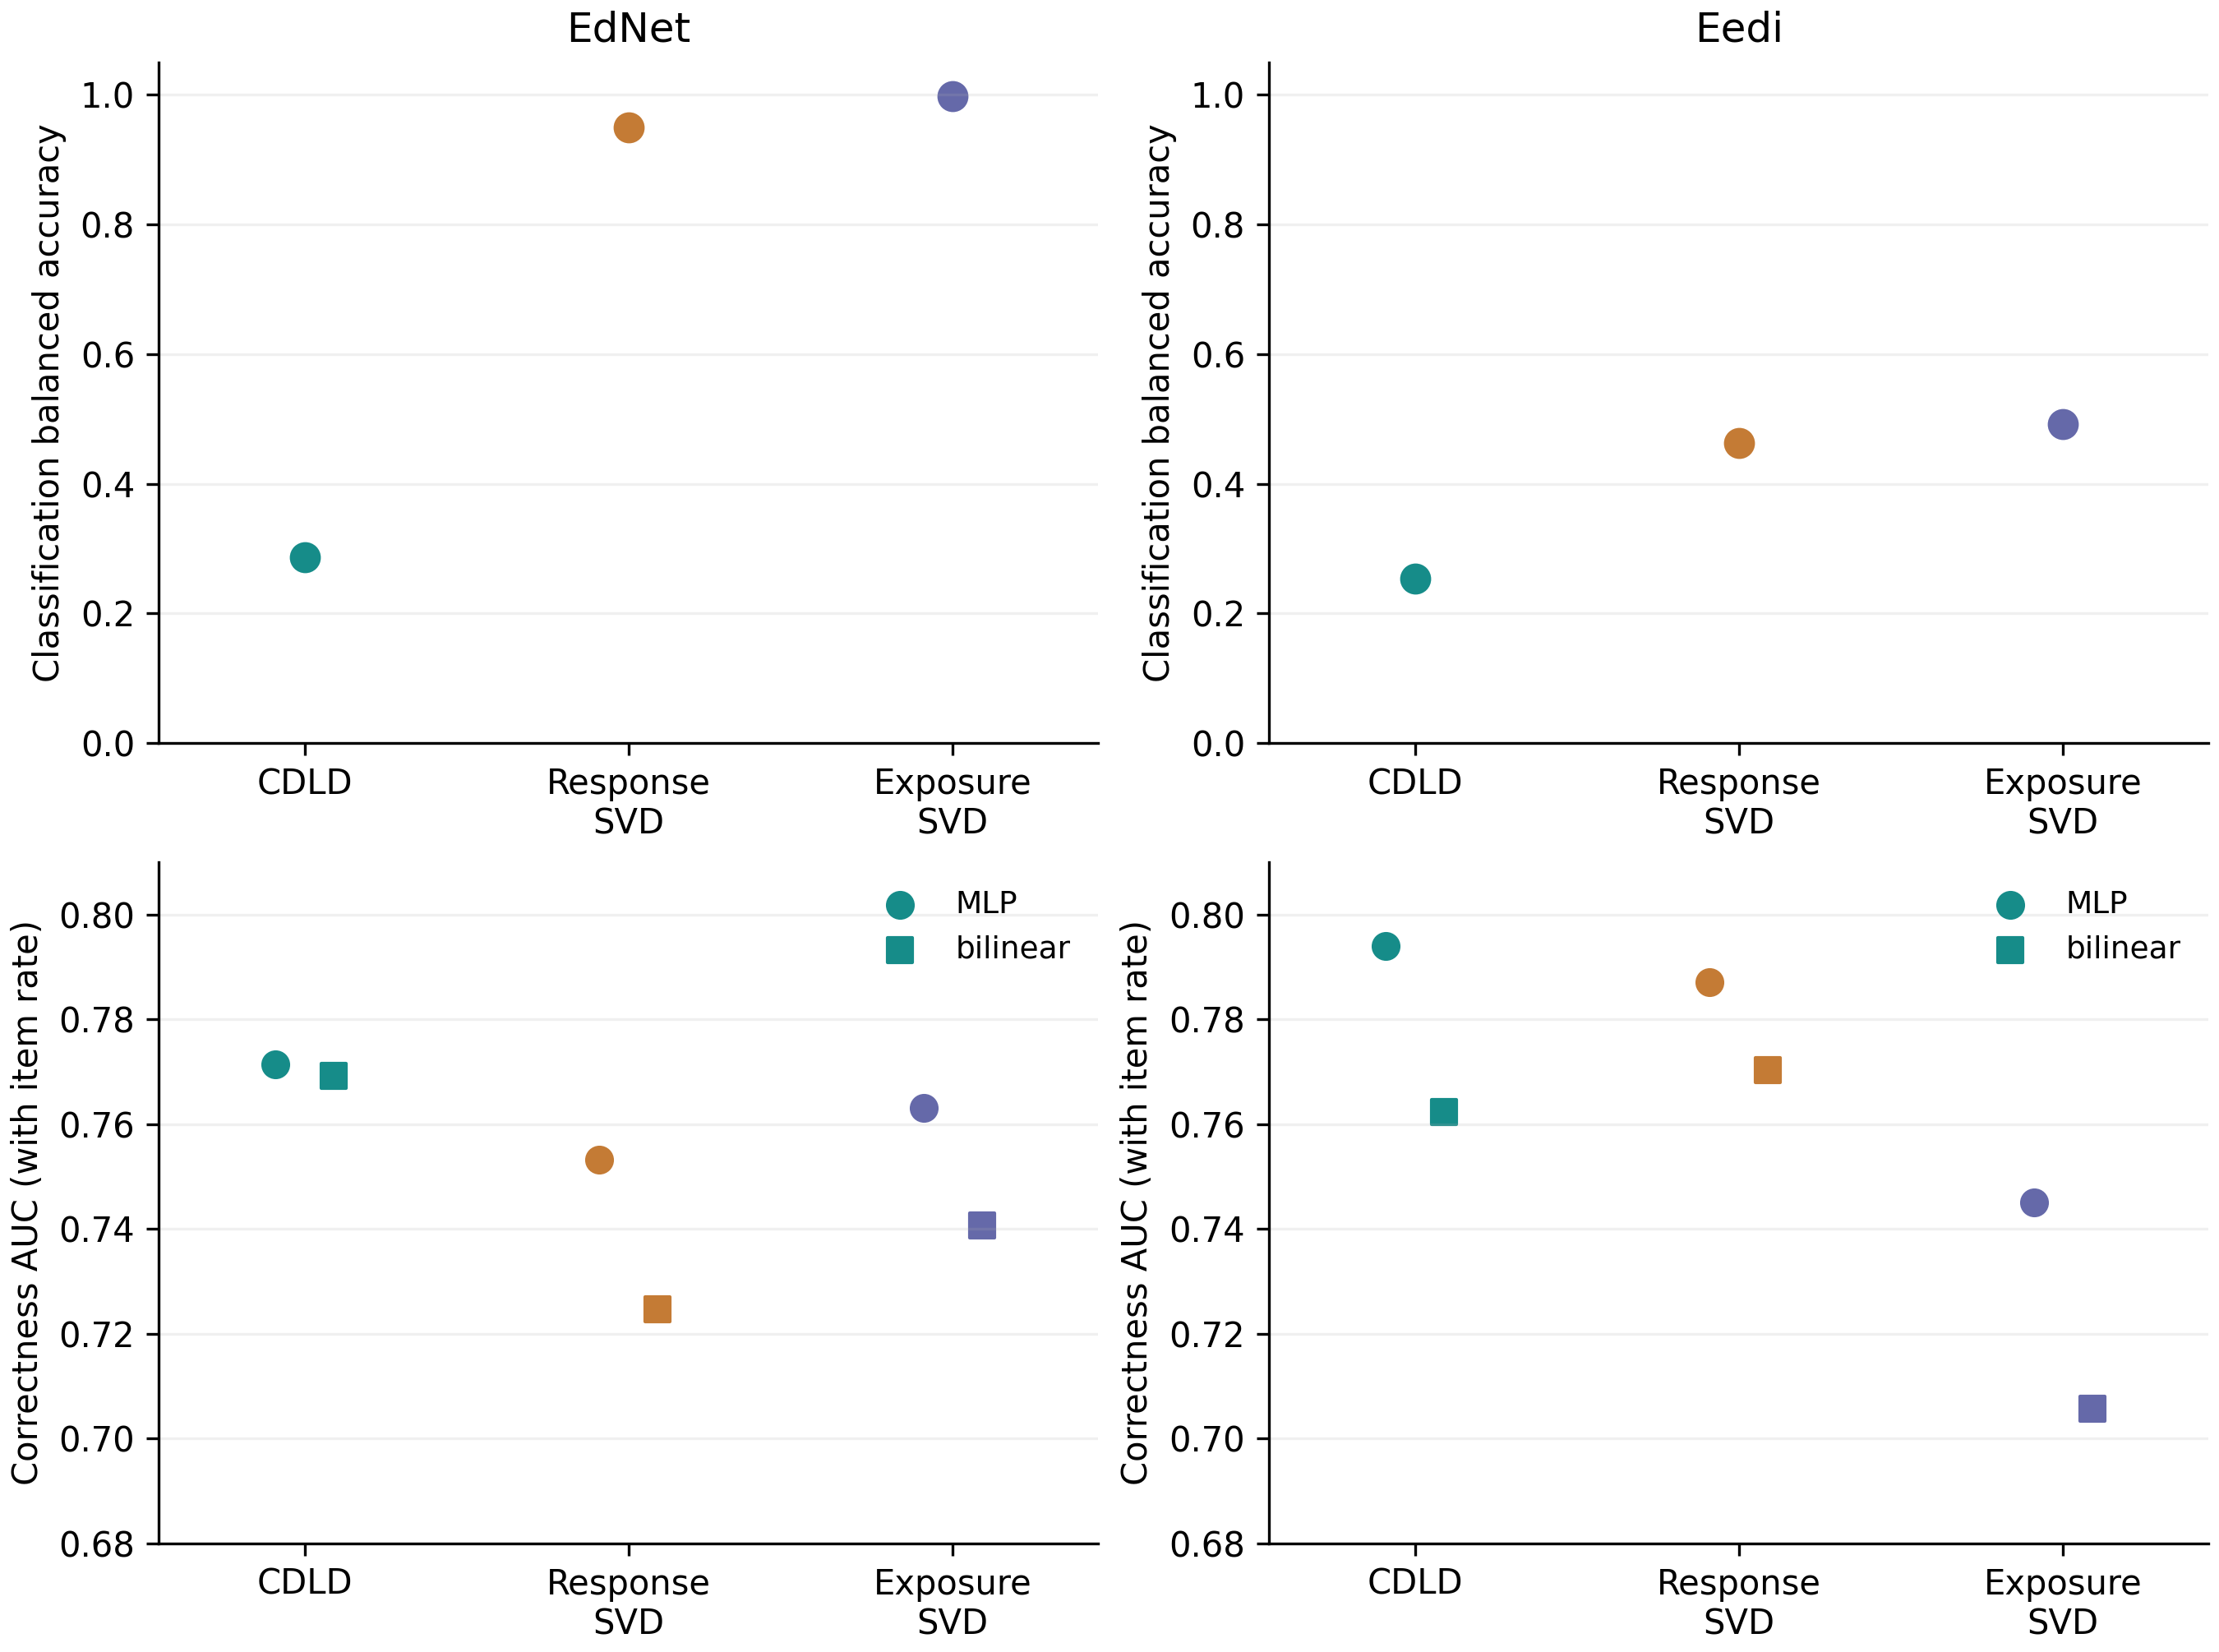

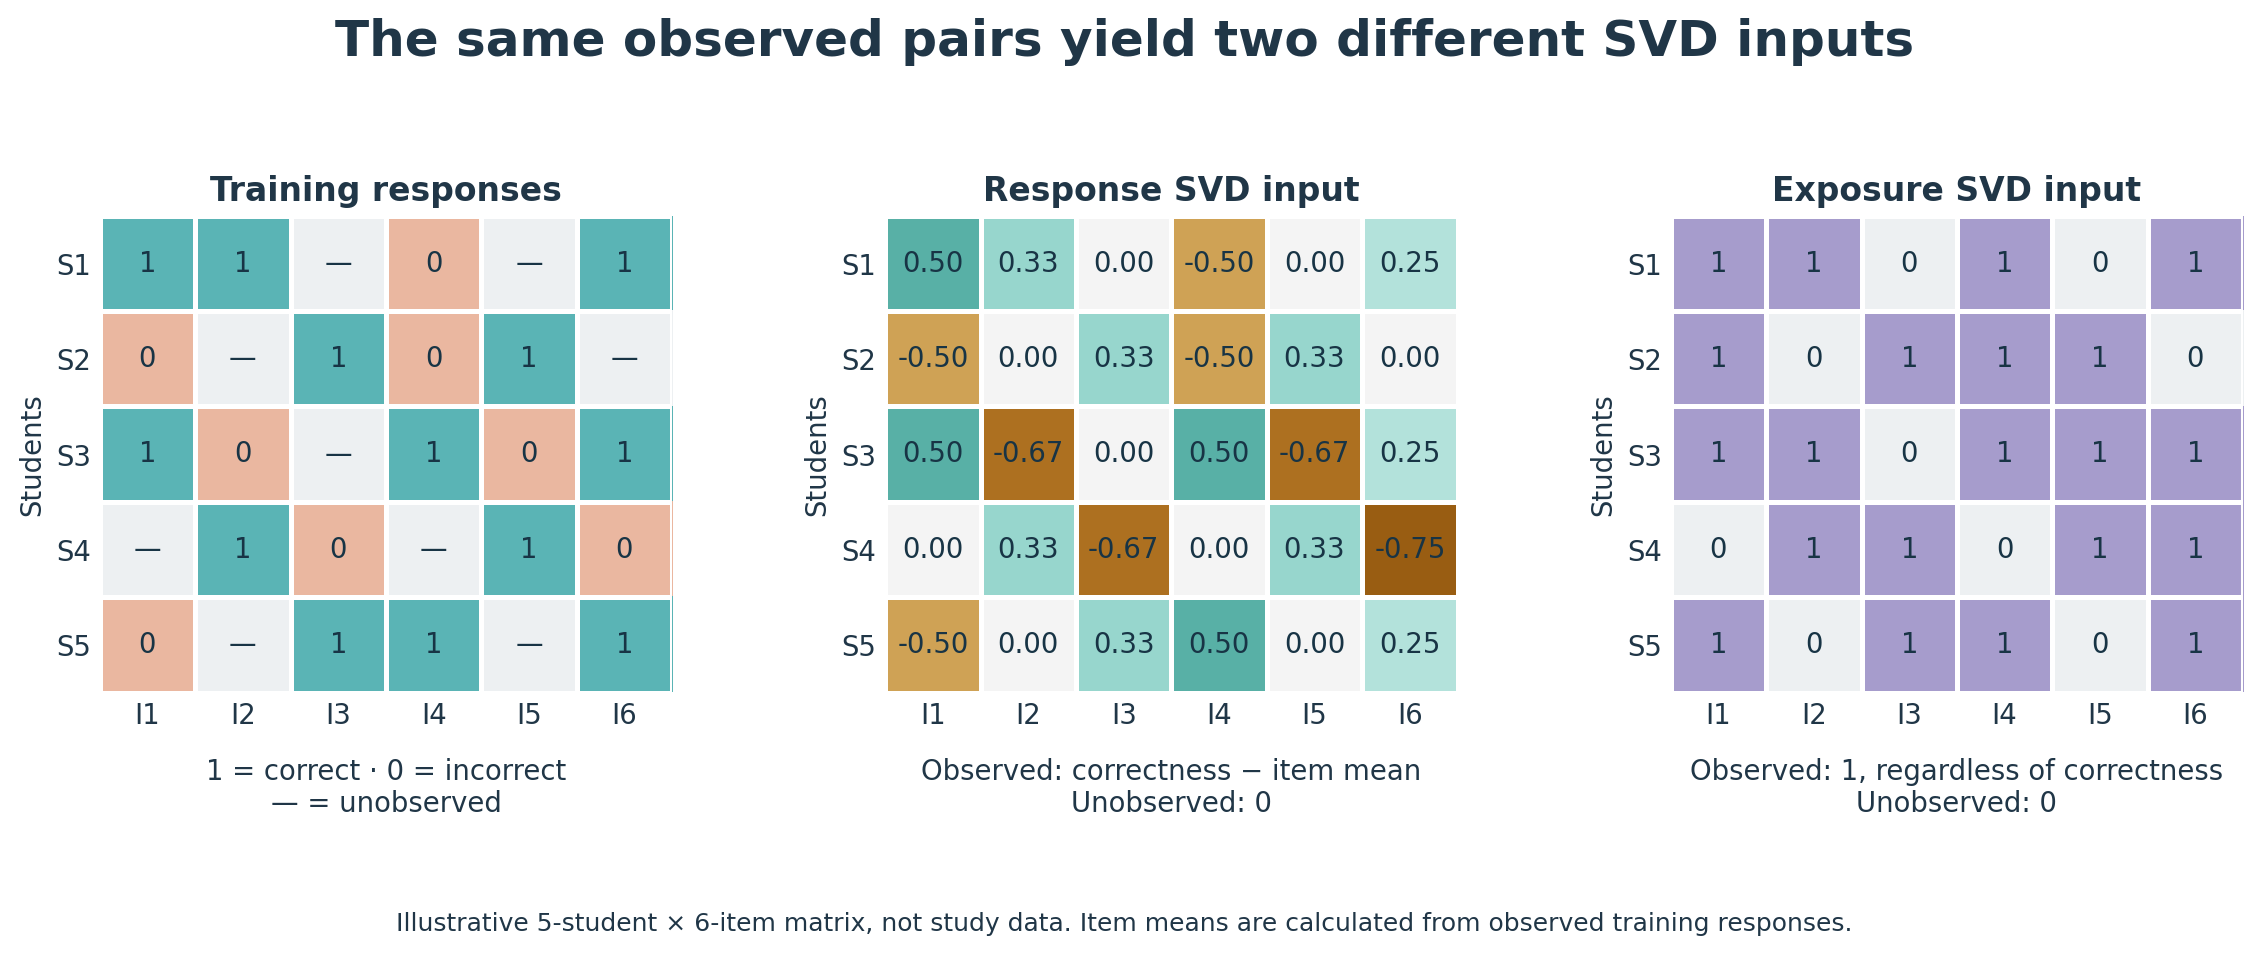

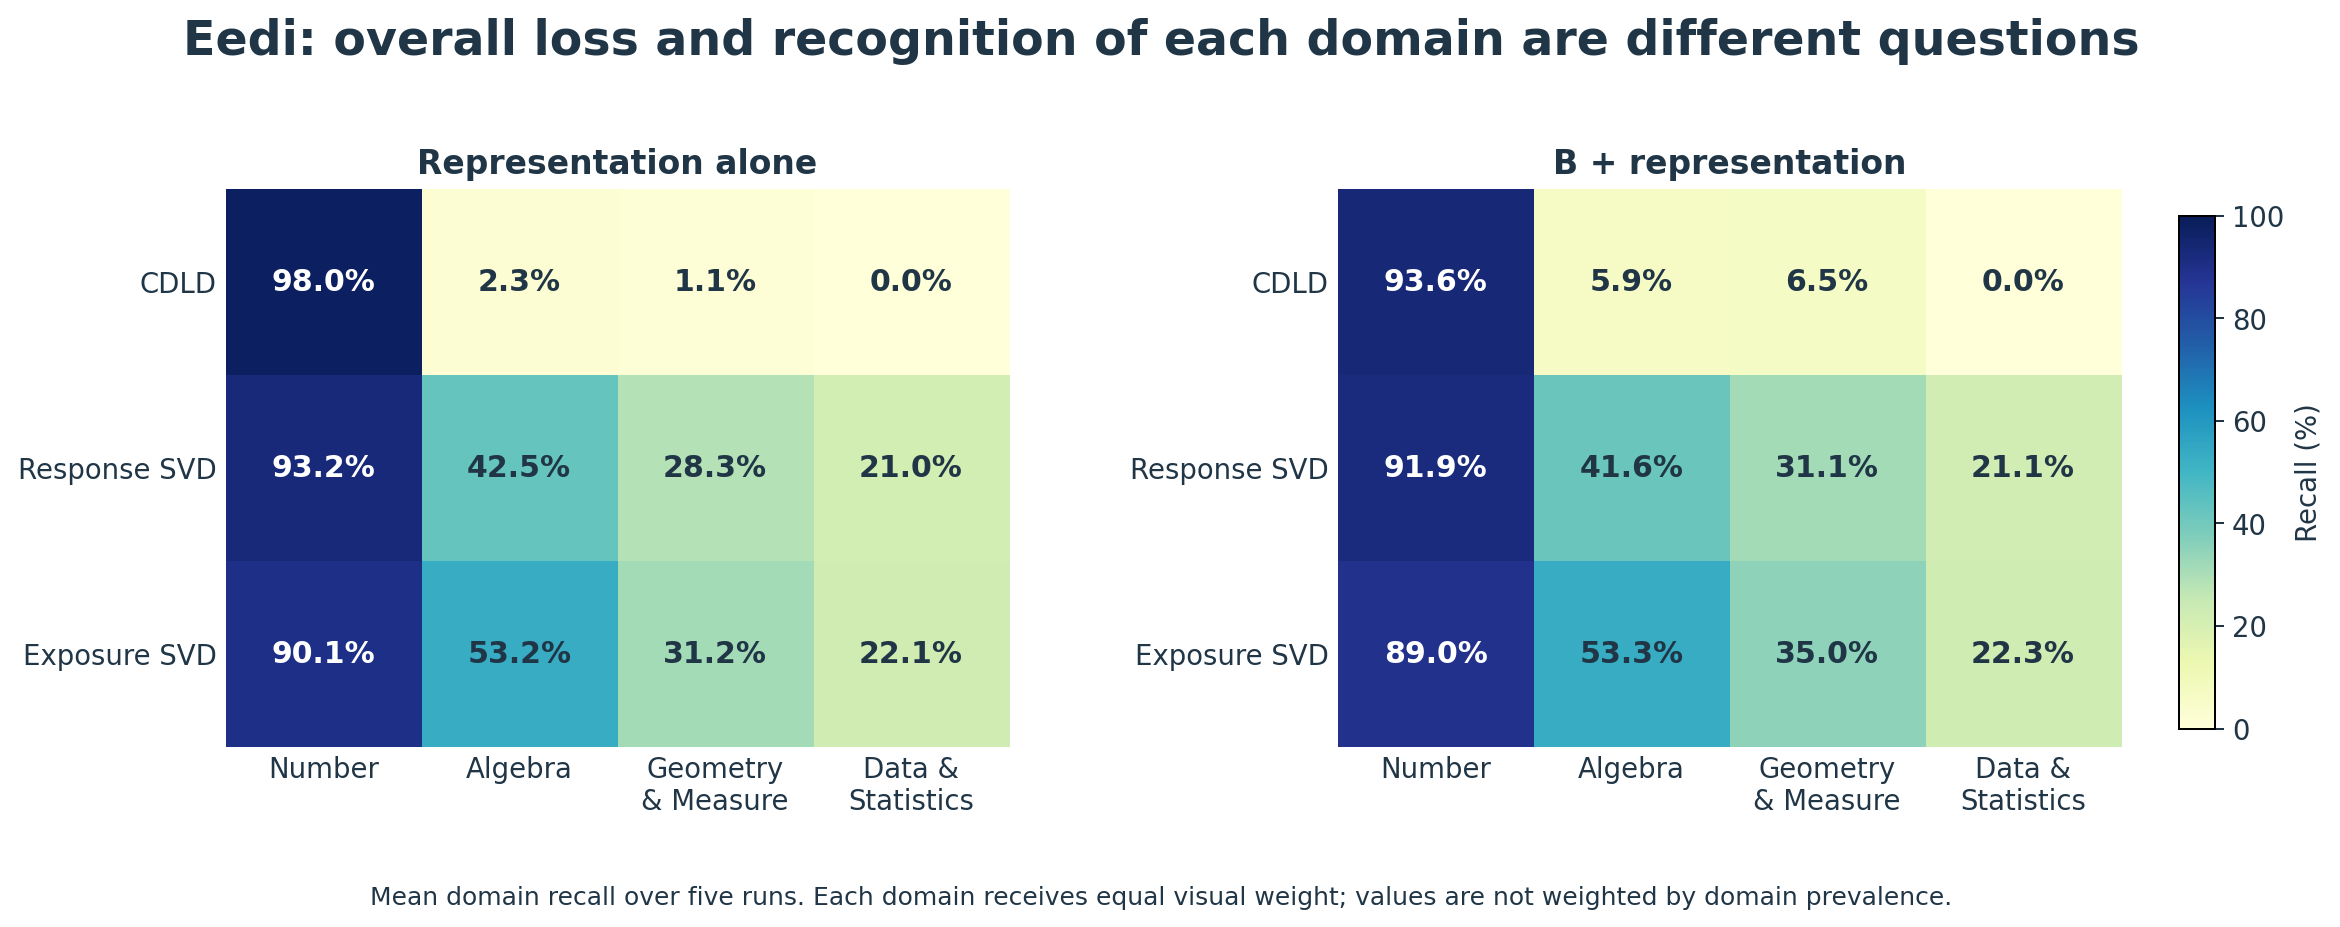

In [5]:
for name in ['figure1','figure2','figure3','figure4','figureS1','figureS2']:
    heading(name)
    display(Image(filename=str(ROOT / 'output' / (name+'.png'))))

## Bundle-grouped classification

In [6]:
table(['Input','Log loss','Balanced accuracy','macro-F1'],
      [[m]+[v[k]['mean'] for k in ['logloss','balanced_accuracy','macro_f1']]
       for m,v in results['EdNet_bundle']['methods'].items()])
contrasts('EdNet_bundle')

Input,Log loss,Balanced accuracy,macro-F1
frequency,1.690533,0.142857,0.085494
B,1.540787,0.183161,0.158641
CDLD,1.367690,0.285572,0.284318
B_CDLD,1.274945,0.340618,0.345348
responseSVD,0.231873,0.946276,0.948255
B_responseSVD,0.223924,0.947294,0.949496
exposureSVD,0.082302,0.991821,0.992243
B_exposureSVD,0.073505,0.988770,0.989454


Contrast (first vs second),Log-loss reduction,95% CI lower,95% CI upper
B_CDLD_vs_B,0.265842,0.252673,0.279943
B_CDLD_vs_B_responseSVD,-1.051021,-1.092956,-1.006654
B_CDLD_vs_B_exposureSVD,-1.201440,-1.232597,-1.165152
CDLD_vs_responseSVD,-1.135817,-1.179510,-1.088926
CDLD_vs_exposureSVD,-1.285389,-1.321320,-1.244512


## Correctness summaries and all paired contrasts
Includes fits with and without the item-rate input. These conditions were fitted separately; their differences do not isolate a causal input effect.

In [7]:
for dataset in ['EdNet','Eedi']:
    heading(dataset)
    table(['Condition','Log loss mean','SD','Minimum','Maximum'],
          [[m]+[v['logloss'][k] for k in ['mean','sd','min','max']]
           for m,v in results[dataset+'_correctness']['methods'].items()])
    contrasts(dataset+'_correctness')

Condition,Log loss mean,SD,Minimum,Maximum
MLP_CDLD_rate,0.522018,0.006800,0.511149,0.528257
MLP_CDLD_original,0.522162,0.006884,0.511191,0.528291
MLP_responseSVD_rate,0.573102,0.013572,0.557299,0.592068
MLP_responseSVD_original,0.583633,0.008046,0.571875,0.593054
MLP_exposureSVD_rate,0.528034,0.007218,0.516098,0.534894
MLP_exposureSVD_original,0.534999,0.006147,0.524333,0.539403
bilinear_CDLD_rate,0.524244,0.006780,0.513899,0.529747
bilinear_CDLD_original,0.524258,0.006777,0.513930,0.529774
bilinear_responseSVD_rate,0.569305,0.003957,0.562639,0.573170
bilinear_responseSVD_original,0.570226,0.003928,0.563626,0.574090


Contrast (first vs second),Log-loss reduction,95% CI lower,95% CI upper
MLP_CDLD_rate_vs_MLP_responseSVD_rate,0.051084,0.047386,0.054892
MLP_CDLD_rate_vs_MLP_exposureSVD_rate,0.006016,0.004074,0.008089
MLP_CDLD_rate_vs_MLP_CDLD_original,0.000144,0.000020,0.000272
MLP_responseSVD_rate_vs_MLP_responseSVD_original,0.010531,0.008084,0.013006
MLP_exposureSVD_rate_vs_MLP_exposureSVD_original,0.006965,0.006114,0.007830
MLP_CDLD_rate_vs_item_rate,0.037998,0.034942,0.041174
MLP_responseSVD_rate_vs_item_rate,-0.013085,-0.017448,-0.008742
MLP_exposureSVD_rate_vs_item_rate,0.031982,0.029543,0.034393
bilinear_CDLD_rate_vs_bilinear_responseSVD_rate,0.045061,0.042627,0.047530
bilinear_CDLD_rate_vs_bilinear_exposureSVD_rate,0.021937,0.019700,0.024370


Condition,Log loss mean,SD,Minimum,Maximum
MLP_CDLD_rate,0.520503,0.007761,0.513199,0.529974
MLP_CDLD_original,0.520205,0.007988,0.511979,0.529507
MLP_responseSVD_rate,0.528061,0.007679,0.519583,0.537137
MLP_responseSVD_original,0.539220,0.008688,0.528622,0.549818
MLP_exposureSVD_rate,0.562753,0.006813,0.552618,0.569700
MLP_exposureSVD_original,0.588099,0.006866,0.579204,0.596446
bilinear_CDLD_rate,0.549298,0.009443,0.540093,0.564114
bilinear_CDLD_original,0.551147,0.010209,0.541985,0.567078
bilinear_responseSVD_rate,0.545230,0.007127,0.537515,0.553628
bilinear_responseSVD_original,0.580012,0.007966,0.570385,0.589466


Contrast (first vs second),Log-loss reduction,95% CI lower,95% CI upper
MLP_CDLD_rate_vs_MLP_responseSVD_rate,0.007558,0.005422,0.009706
MLP_CDLD_rate_vs_MLP_exposureSVD_rate,0.042250,0.038482,0.045984
MLP_CDLD_rate_vs_MLP_CDLD_original,-0.000298,-0.000754,0.000142
MLP_responseSVD_rate_vs_MLP_responseSVD_original,0.011159,0.009644,0.012651
MLP_exposureSVD_rate_vs_MLP_exposureSVD_original,0.025346,0.023605,0.027133
MLP_CDLD_rate_vs_item_rate,0.078451,0.073966,0.083131
MLP_responseSVD_rate_vs_item_rate,0.070893,0.066499,0.075366
MLP_exposureSVD_rate_vs_item_rate,0.036201,0.033166,0.039348
bilinear_CDLD_rate_vs_bilinear_responseSVD_rate,-0.004068,-0.007220,-0.001043
bilinear_CDLD_rate_vs_bilinear_exposureSVD_rate,0.040255,0.036394,0.044110


## Response counts and evaluation eligibility

In [8]:
for dataset, v in results['samples'].items():
    heading(dataset)
    print(f"Eligible students: {v['eligible_percent']:.2f}%")
    table(['Population','n','Mean','Q1','Median','Q3','Minimum','Maximum'],
          [[k]+[v[k][m] for m in ['n','mean','p25','median','p75','min','max']]
           for k in ['all','eligible','evaluation_unique']])
    table(['Run','n','Mean','Q1','Median','Q3','Minimum','Maximum'],
          [[k]+[z[m] for m in ['n','mean','p25','median','p75','min','max']]
           for k,z in v['per_run'].items()])

Eligible students: 15.55%


Population,n,Mean,Q1,Median,Q3,Minimum,Maximum
all,784309,101.879751,7.000000,10.000000,37.000000,0,11466
eligible,121959,568.237285,131.000000,249.000000,588.000000,80,11466
evaluation_unique,2480,559.647177,131.000000,258.000000,583.250000,80,9190


Run,n,Mean,Q1,Median,Q3,Minimum,Maximum
42,500,589.092000,128.000000,266.000000,567.500000,80,7598
43,500,575.586000,131.750000,265.000000,617.250000,80,8160
44,500,580.424000,125.000000,260.000000,625.500000,80,7273
45,500,525.462000,140.000000,251.000000,554.000000,80,5228
46,500,523.136000,128.500000,235.500000,512.000000,80,9190


Eligible students: 55.42%


Population,n,Mean,Q1,Median,Q3,Minimum,Maximum
all,118971,133.375781,57.000000,88.000000,159.000000,29,2445
eligible,65930,195.879615,105.000000,147.000000,234.000000,80,2445
evaluation_unique,2468,200.095219,108.000000,148.500000,236.000000,80,2370


Run,n,Mean,Q1,Median,Q3,Minimum,Maximum
42,500,199.330000,104.000000,148.000000,242.250000,80,1323
43,500,202.534000,108.000000,148.000000,248.750000,80,1067
44,500,194.504000,110.000000,150.000000,223.250000,80,1321
45,500,213.650000,112.000000,156.000000,258.000000,80,1716
46,500,190.572000,106.000000,143.000000,218.500000,80,2370


## Eedi domains
Confusion matrices are row-normalized within each run and then averaged. Rows are true categories, columns are predicted categories; values are percentages.

In [9]:
labels=['Number','Algebra','Geometry and Measure','Data and Statistics']
v=results['domains']['B']
table(['Domain','Minimum n','Maximum n','Mean prevalence (%)'],
      [[label,v['n_min'][i],v['n_max'][i],100*v['mean_prevalence'][i]] for i,label in enumerate(labels)])
for method,v in results['domains'].items():
    heading(method)
    table(['True / predicted']+labels, [[label]+[100*x for x in v['mean_row_normalized_confusion'][i]] for i,label in enumerate(labels)])

Domain,Minimum n,Maximum n,Mean prevalence (%)
Number,11893,11901,44.419389
Algebra,5453,5455,20.360941
Geometry and Measure,6824,6829,25.486829
Data and Statistics,2607,2607,9.732842


True / predicted,Number,Algebra,Geometry and Measure,Data and Statistics
Number,95.644645,0.633723,3.721632,0.000000
Algebra,93.831819,0.737099,5.431082,0.000000
Geometry and Measure,92.465018,0.946276,6.588706,0.000000
Data and Statistics,91.845033,1.396241,6.758727,0.000000


True / predicted,Number,Algebra,Geometry and Measure,Data and Statistics
Number,97.962647,1.317887,0.719466,0.000000
Algebra,96.816782,2.262741,0.920478,0.000000
Geometry and Measure,96.622511,2.252634,1.124855,0.000000
Data and Statistics,96.524741,2.247794,1.227465,0.000000


True / predicted,Number,Algebra,Geometry and Measure,Data and Statistics
Number,93.647765,2.674362,3.677874,0.000000
Algebra,88.470263,5.929907,5.599830,0.000000
Geometry and Measure,89.219356,4.262395,6.518249,0.000000
Data and Statistics,88.722670,4.687380,6.589950,0.000000


True / predicted,Number,Algebra,Geometry and Measure,Data and Statistics
Number,93.156827,3.237541,2.968547,0.637085
Algebra,49.290341,42.484183,7.125328,1.100147
Geometry and Measure,62.773224,7.558441,28.262121,1.406213
Data and Statistics,59.647104,8.270042,11.077867,21.004987


True / predicted,Number,Algebra,Geometry and Measure,Data and Statistics
Number,91.874266,3.089610,4.355339,0.680785
Algebra,47.500770,41.600385,9.857368,1.041476
Geometry and Measure,60.482283,7.077977,31.095056,1.344683
Data and Statistics,56.233218,7.825086,14.836977,21.104718


True / predicted,Number,Algebra,Geometry and Measure,Data and Statistics
Number,90.050429,5.390820,3.765342,0.793409
Algebra,37.016394,53.173941,8.408805,1.400860
Geometry and Measure,55.712759,11.270275,31.200595,1.816370
Data and Statistics,49.881089,10.379747,17.598773,22.140391


True / predicted,Number,Algebra,Geometry and Measure,Data and Statistics
Number,88.967892,5.281563,4.928560,0.821985
Algebra,34.306344,53.327970,10.986831,1.378856
Geometry and Measure,52.123970,11.100357,34.968102,1.807572
Data and Statistics,45.554277,10.533180,21.580361,22.332183


## Run-level results
Complete seed-level metrics used for means, sample standard deviations and ranges.

In [10]:
for file in sorted((ROOT/'output').glob('*_runs.csv')):
    heading(file.stem)
    with file.open() as f:
        reader=csv.reader(f); headers=next(reader); rows=list(reader)
    table(headers, rows)

seed,method,logloss,auc,brier,accuracy
42,item_rate,0.5654495687657578,0.7123199507368837,0.19171170464020723,0.71255
42,CDLD_logit,0.5285717196863877,0.7655726737675899,0.17706243565996932,0.7348
42,CDLD_raw,0.5287127663773271,0.7655546895430556,0.17710860345238877,0.7344
42,responseSVD_logit,0.5567894687414257,0.7392342761107749,0.1869713673600722,0.72005
42,responseSVD_raw,0.5696036507730111,0.72435368481679,0.191608779849073,0.71095
42,exposureSVD_logit,0.5508268137990014,0.734595040508612,0.18580713514033953,0.71915
42,exposureSVD_raw,0.551881905024807,0.7341519456398357,0.18596635908537518,0.71885
43,item_rate,0.5584022246623714,0.7177398710311325,0.18881814094625118,0.71665
43,CDLD_logit,0.520519443113543,0.7720600524519289,0.17388725939897112,0.7399
43,CDLD_raw,0.5207859817444757,0.7717665450163305,0.17398574504495515,0.73975


seed,method,n,logloss,balanced_accuracy,macro_f1
42,frequency,12267,1.6905305160082267,0.14285714285714285,0.08549394050679397
42,B,12267,1.5394557488449097,0.18300295743467807,0.15841382359535275
42,CDLD,12267,1.491449278816828,0.22318256095659464,0.21887217269835535
42,B_CDLD,12267,1.3874027463276646,0.29514592779698307,0.3020314633016323
42,responseSVD,12267,0.22991068547188323,0.9474464249379488,0.9494737048855632
42,B_responseSVD,12267,0.21978038672520167,0.9473002210198419,0.9494147708272115
42,exposureSVD,12267,0.08403725093729375,0.9926776739762954,0.9929789977625484
42,B_exposureSVD,12267,0.07364818426706558,0.989252357161992,0.9899378605773121
43,frequency,12267,1.6905305160082267,0.14285714285714285,0.08549394050679397
43,B,12267,1.5444324977095563,0.1828044773212775,0.15782979320684926


seed,method,logloss,auc,brier,accuracy
42,MLP_CDLD_rate,0.5282569888765032,0.7659705918090394,0.1768580870012696,0.735
42,MLP_CDLD_original,0.5282914580069641,0.7662816733637984,0.17677216871667398,0.7357
42,MLP_responseSVD_rate,0.5741446412853617,0.7511008991827706,0.18608499032100245,0.7279
42,MLP_responseSVD_original,0.5807033880471812,0.745865088152579,0.18673475409607776,0.7297
42,MLP_exposureSVD_rate,0.5348943658352366,0.7559388433924052,0.17949092460489702,0.73275
42,MLP_exposureSVD_original,0.5394030908966032,0.7502920700667665,0.18115849028176578,0.7287
42,bilinear_CDLD_rate,0.5287127663773271,0.7655546895430556,0.17710860345238877,0.7344
42,bilinear_CDLD_original,0.5287200834959069,0.7655471088509418,0.177111737452388,0.73435
42,bilinear_responseSVD_rate,0.5696036507730111,0.72435368481679,0.191608779849073,0.71095
42,bilinear_responseSVD_original,0.5704381509681108,0.7230401307157179,0.1919245319036961,0.7101


seed,method,n,logloss,balanced_accuracy,macro_f1
42,frequency,12267,1.6902657424184009,0.14285714285714285,0.08549394050679397
42,B,12267,1.5374902319938695,0.1836930556593425,0.15939800852694783
42,CDLD,12267,1.493514401672729,0.22718966844760466,0.22409731474501063
42,B_CDLD,12267,1.3884102787655146,0.29831275227311566,0.30467912325003244
42,responseSVD,12267,0.21193578624915568,0.950123542554652,0.9519513223992622
42,B_responseSVD,12267,0.18826753556822776,0.9515236075461353,0.9531813535254278
42,exposureSVD,12267,0.0374695824963353,0.9975830709492153,0.9967288833343345
42,B_exposureSVD,12267,0.036047713519698175,0.9971779772415308,0.9962491702097911
43,frequency,12267,1.6902657424184009,0.14285714285714285,0.08549394050679397
43,B,12267,1.5425652991398997,0.18295538051623547,0.15803928463023226


seed,method,logloss,auc,brier,accuracy
42,item_rate,0.5973760856515579,0.6863180494854344,0.20565478687001346,0.68115
42,CDLD_logit,0.5503395786843092,0.7575347967388285,0.1865192617212282,0.71205
42,CDLD_raw,0.5508926992556495,0.7570214707372187,0.18671361486389523,0.71135
42,responseSVD_logit,0.5438449963499884,0.7667352963478937,0.1832689137279911,0.7236
42,responseSVD_raw,0.5445004035725883,0.766946735603437,0.18348366750863013,0.7232
42,exposureSVD_logit,0.5880102094761965,0.7030203787601986,0.2016728468436013,0.68595
42,exposureSVD_raw,0.5884829511248826,0.7031919557070924,0.20175686019490557,0.68585
43,item_rate,0.6046514250823762,0.6911401475620993,0.20909420356076971,0.6674
43,CDLD_logit,0.541363460002722,0.7801634221916958,0.1829883011565805,0.7211
43,CDLD_raw,0.542235976582401,0.7797802812687438,0.18325521662737032,0.72045


seed,method,logloss,auc,brier,accuracy
42,MLP_CDLD_rate,0.5189895470054504,0.7935308126591234,0.17375245032837625,0.73795
42,MLP_CDLD_original,0.5186117144911496,0.7936406370510567,0.17360522565739858,0.7402
42,MLP_responseSVD_rate,0.5288589294283129,0.7842470159709019,0.17721546799339769,0.7338
42,MLP_responseSVD_original,0.5411425617518089,0.7702592254053204,0.18192144977966143,0.72445
42,MLP_exposureSVD_rate,0.5628334292902339,0.7420787792264559,0.19117675290447989,0.7085
42,MLP_exposureSVD_original,0.586579747325699,0.709010063795169,0.2008176942536625,0.692
42,bilinear_CDLD_rate,0.5508926992556495,0.7570214707372187,0.18671361486389523,0.71135
42,bilinear_CDLD_original,0.5531283829830238,0.7545096184776463,0.1877015390478059,0.71065
42,bilinear_responseSVD_rate,0.5445004035725883,0.766946735603437,0.18348366750863013,0.7232
42,bilinear_responseSVD_original,0.5800649909966326,0.7258568280869563,0.19764787512997894,0.69575


seed,method,n,logloss,balanced_accuracy,macro_f1
42,frequency,26789,1.2596268946963713,0.25,0.15379943137761695
42,B,26789,1.2420739970733858,0.2573509373043805,0.18405603850288546
42,CDLD,26789,1.24520185663602,0.25199695852231424,0.16347603301882374
42,B_CDLD,26789,1.239503373020246,0.26464301406390645,0.20365594676485965
42,responseSVD,26789,0.9564113312951288,0.46123462638555346,0.48519455239442066
42,B_responseSVD,26789,0.9515784654623859,0.46308335241801324,0.4878112868536555
42,exposureSVD,26789,0.9129928214681079,0.4909966906808122,0.5105594723126589
42,B_exposureSVD,26789,0.9101637828579388,0.498446190338521,0.5188924623352791
43,frequency,26789,1.2596309977113718,0.25,0.15379048308304685
43,B,26789,1.2419167462281147,0.25773506660507606,0.18470728682443788


## Classification variability
Means, sample standard deviations and ranges across five runs. Seed-level values are displayed above.

In [11]:
for key in ['EdNet_item','EdNet_bundle','Eedi_item']:
    heading(key)
    for metric in ['logloss','balanced_accuracy','macro_f1']:
        heading(metric)
        table(['Condition','Mean','SD','Minimum','Maximum'], [[m]+[v[metric][k] for k in ['mean','sd','min','max']] for m,v in results[key]['methods'].items()])

Condition,Mean,SD,Minimum,Maximum
frequency,1.690269,0.000044,1.690211,1.690334
B,1.538391,0.003956,1.532787,1.542565
CDLD,1.367956,0.180245,1.107281,1.528005
B_CDLD,1.274364,0.165072,1.036618,1.421690
responseSVD,0.212095,0.000488,0.211338,0.212537
B_responseSVD,0.203470,0.009376,0.188268,0.212307
exposureSVD,0.043639,0.005396,0.037470,0.050143
B_exposureSVD,0.040277,0.004564,0.036048,0.047022


Condition,Mean,SD,Minimum,Maximum
frequency,0.142857,0.000000,0.142857,0.142857
B,0.184249,0.001034,0.182955,0.185704
CDLD,0.286490,0.080560,0.216201,0.400501
B_CDLD,0.343751,0.064468,0.291494,0.435251
responseSVD,0.948909,0.001859,0.946112,0.950996
B_responseSVD,0.950138,0.001301,0.948508,0.951524
exposureSVD,0.997449,0.000496,0.996794,0.997929
B_exposureSVD,0.996664,0.000735,0.995543,0.997428


Condition,Mean,SD,Minimum,Maximum
frequency,0.085494,0.000004,0.085487,0.085499
B,0.160279,0.001752,0.158039,0.162497
CDLD,0.285221,0.085261,0.209203,0.405535
B_CDLD,0.348266,0.065184,0.295592,0.439843
responseSVD,0.950643,0.001556,0.948235,0.952082
B_responseSVD,0.951852,0.001294,0.950446,0.953181
exposureSVD,0.996682,0.000450,0.996193,0.997332
B_exposureSVD,0.995890,0.000686,0.994878,0.996713


Condition,Mean,SD,Minimum,Maximum
frequency,1.690533,0.000044,1.690475,1.690599
B,1.540787,0.003190,1.536652,1.544432
CDLD,1.367690,0.180753,1.105825,1.529863
B_CDLD,1.274945,0.165652,1.036947,1.424808
responseSVD,0.231873,0.002816,0.228212,0.235021
B_responseSVD,0.223924,0.002599,0.219780,0.226853
exposureSVD,0.082302,0.008169,0.073562,0.093512
B_exposureSVD,0.073505,0.001597,0.071375,0.075118


Condition,Mean,SD,Minimum,Maximum
frequency,0.142857,0.000000,0.142857,0.142857
B,0.183161,0.000337,0.182804,0.183588
CDLD,0.285572,0.080959,0.216579,0.401539
B_CDLD,0.340618,0.064478,0.283173,0.431671
responseSVD,0.946276,0.001104,0.944493,0.947446
B_responseSVD,0.947294,0.000556,0.946362,0.947814
exposureSVD,0.991821,0.001194,0.990622,0.993420
B_exposureSVD,0.988770,0.000730,0.987730,0.989637


Condition,Mean,SD,Minimum,Maximum
frequency,0.085494,0.000004,0.085487,0.085499
B,0.158641,0.000644,0.157830,0.159528
CDLD,0.284318,0.085941,0.209756,0.407283
B_CDLD,0.345348,0.064603,0.287387,0.436398
responseSVD,0.948255,0.001176,0.946526,0.949474
B_responseSVD,0.949496,0.000763,0.948300,0.950193
exposureSVD,0.992243,0.001100,0.990987,0.993731
B_exposureSVD,0.989454,0.000720,0.988516,0.990326


Condition,Mean,SD,Minimum,Maximum
frequency,1.259665,0.000061,1.259610,1.259752
B,1.242055,0.000485,1.241548,1.242852
CDLD,1.245248,0.001292,1.243695,1.247043
B_CDLD,1.238122,0.002414,1.235567,1.241523
responseSVD,0.954795,0.001642,0.953420,0.956735
B_responseSVD,0.949742,0.001648,0.948211,0.951578
exposureSVD,0.913178,0.000490,0.912559,0.913711
B_exposureSVD,0.910196,0.000485,0.909591,0.910760


Condition,Mean,SD,Minimum,Maximum
frequency,0.250000,0.000000,0.250000,0.250000
B,0.257426,0.000268,0.257127,0.257735
CDLD,0.253376,0.003368,0.250627,0.258600
B_CDLD,0.265240,0.004056,0.258475,0.268403
responseSVD,0.462270,0.001089,0.461235,0.464052
B_responseSVD,0.464186,0.001595,0.463045,0.466686
exposureSVD,0.491413,0.000550,0.490997,0.492214
B_exposureSVD,0.498990,0.001027,0.497972,0.500669


Condition,Mean,SD,Minimum,Maximum
frequency,0.153786,0.000017,0.153760,0.153799
B,0.184356,0.000517,0.183795,0.185064
CDLD,0.168960,0.011583,0.158665,0.185925
B_CDLD,0.205304,0.010243,0.188213,0.213330
responseSVD,0.485649,0.001329,0.484731,0.488002
B_responseSVD,0.488824,0.001859,0.487611,0.492009
exposureSVD,0.510782,0.000675,0.509995,0.511570
B_exposureSVD,0.519358,0.001138,0.517948,0.520999


## Bilinear logit-rate sensitivity
The training item proportion correct was clipped to [0.000001, 0.999999] and logit-transformed without further normalization. This is a supplementary bilinear comparison using the same frozen vectors and splits. MLP fits retain raw-rate inputs. Raw–logit differences include refitting and model-selection variation.

In [12]:
sensitivity=json.loads((ROOT/'output/bilinear_sensitivity.json').read_text())
for dataset,v in sensitivity.items():
    heading(dataset)
    table(['Condition','Log loss','SD','AUC','Brier','Accuracy'], [[m,z['logloss']['mean'],z['logloss']['sd'],z['auc']['mean'],z['brier']['mean'],z['accuracy']['mean']] for m,z in v['methods'].items()])
    table(['Contrast','Log-loss reduction','Lower 95%','Upper 95%'], [[m,z['logloss_reduction']]+z['conditional_95_CI'] for m,z in v['contrasts'].items()])

Condition,Log loss,SD,AUC,Brier,Accuracy
item_rate,0.560017,0.006130,0.718222,0.189383,0.715890
CDLD_logit,0.523869,0.006939,0.769590,0.175135,0.738510
CDLD_raw,0.524244,0.006780,0.769235,0.175263,0.738500
responseSVD_logit,0.555361,0.004465,0.741575,0.185945,0.722070
responseSVD_raw,0.569305,0.003957,0.724636,0.190988,0.712930
exposureSVD_logit,0.544854,0.006019,0.741572,0.183263,0.725580
exposureSVD_raw,0.546181,0.005774,0.740672,0.183539,0.725390


Contrast,Log-loss reduction,Lower 95%,Upper 95%
CDLD_logit_vs_responseSVD_logit,0.031491,0.029274,0.033807
CDLD_logit_vs_exposureSVD_logit,0.020984,0.018768,0.023430
CDLD_logit_vs_CDLD_raw,0.000374,0.000290,0.000463
responseSVD_logit_vs_responseSVD_raw,0.013944,0.013374,0.014518
exposureSVD_logit_vs_exposureSVD_raw,0.001327,0.001020,0.001632
CDLD_logit_vs_item_rate,0.036147,0.033282,0.039165
responseSVD_logit_vs_item_rate,0.004656,0.002403,0.006913
exposureSVD_logit_vs_item_rate,0.015163,0.013332,0.017002


Condition,Log loss,SD,AUC,Brier,Accuracy
item_rate,0.598954,0.003562,0.687479,0.206497,0.674850
CDLD_logit,0.548641,0.009413,0.762685,0.185748,0.715060
CDLD_raw,0.549298,0.009443,0.762344,0.185953,0.714780
responseSVD_logit,0.544402,0.007142,0.770119,0.183354,0.723700
responseSVD_raw,0.545230,0.007127,0.770349,0.183595,0.722930
exposureSVD_logit,0.588769,0.003720,0.705722,0.202068,0.683140
exposureSVD_raw,0.589553,0.003862,0.705723,0.202262,0.682800


Contrast,Log-loss reduction,Lower 95%,Upper 95%
CDLD_logit_vs_responseSVD_logit,-0.004239,-0.007355,-0.001232
CDLD_logit_vs_exposureSVD_logit,0.040128,0.036263,0.043990
CDLD_logit_vs_CDLD_raw,0.000657,0.000496,0.000818
responseSVD_logit_vs_responseSVD_raw,0.000828,0.000542,0.001101
exposureSVD_logit_vs_exposureSVD_raw,0.000784,0.000492,0.001064
CDLD_logit_vs_item_rate,0.050313,0.046310,0.054332
responseSVD_logit_vs_item_rate,0.054552,0.051252,0.058003
exposureSVD_logit_vs_item_rate,0.010185,0.008745,0.011621
